# Lab 5-A（04）：狀態與 checkpoint——把迴圈變成可以存檔的狀態圖

**目標**：把 02 的迴圈搬進 LangGraph 的 `StateGraph`，加上 `InMemorySaver`，
讓值班對話可以中斷、換一個 thread、再接回來，也能回到過去的某一步重跑。

**你會學到**
- StateGraph 三要素：狀態（TypedDict）、節點（函式）、邊（含條件邊）
- reducer：多個節點更新同一個欄位時，要「追加」還是「覆蓋」
- checkpointer＋`thread_id`：每走一步存一張快照，同一個 thread 才記得前文
- 回到過去的快照（時光旅行）與 `recursion_limit` 保險絲

**前置**：Lab 5-02；先讀 `00_concepts.md` 第 4 節（狀態機與 checkpoint）。

**對應投影片**：「為什麼需要狀態圖」「StateGraph 三要素」「條件邊就是路由」「Reducer 合併規則」「Checkpointer 與 thread」「時光旅行與分岔」

![checkpoint 快照概念圖](images/checkpoint.jpg)

*圖：每個 thread_id 是一捲底片，每走一步存一格快照，越往後訊息越多；兩捲都存在 InMemorySaver。從 step 2 那格拿出來重跑，就分岔出一條新路（時光旅行）。*

## 先對一下名詞

02 的 while 迴圈其實就是一個狀態機。`00_concepts.md` 第 4 節用一個 dict 寫出了這台狀態機（約 40 行），這裡只列對應關係：

| 手寫狀態機 | LangGraph |
|---|---|
| 狀態 dict | `TypedDict` 定義的 State |
| `merge` 裡的「messages 用追加」 | reducer：`Annotated[list, add_messages]` |
| `NODES` | `builder.add_node` |
| `EDGES` 的字串／函式 | `add_edge`／`add_conditional_edges` |
| `snapshots` | checkpointer（`InMemorySaver`） |
| `max_steps` | `recursion_limit` |

## Step 1：Reducer——不寫清楚就會覆蓋

先看一個最小的例子。兩個欄位都收到更新：沒有 reducer 的欄位被**覆蓋**，有 `operator.add` 的欄位被**追加**。
兩個節點平行更新同一個欄位時，這個差別就會造成資料遺失。

In [1]:
import operator
from typing import Annotated, TypedDict

from langgraph.graph import END, START, StateGraph


class Demo(TypedDict):
    overwrite: list
    appended: Annotated[list, operator.add]


def step_a(state: Demo) -> dict:
    return {"overwrite": ["A"], "appended": ["A"]}


def step_b(state: Demo) -> dict:
    return {"overwrite": ["B"], "appended": ["B"]}


demo = StateGraph(Demo)
demo.add_node("a", step_a)
demo.add_node("b", step_b)
demo.add_edge(START, "a")
demo.add_edge("a", "b")
demo.add_edge("b", END)
print(demo.compile().invoke({"overwrite": ["起點"], "appended": ["起點"]}))

{'overwrite': ['B'], 'appended': ['起點', 'A', 'B']}


## Step 2：真的值班 agent——工具

工具用 LangChain 的 `@tool`，參數一樣用 Pydantic（`args_schema`），說明文字就是 docstring。

In [2]:
from langchain_core.tools import tool

import oncall_tools as ot


@tool(args_schema=ot.ReadLogsArgs)
def read_logs(service=None, level=None, keyword=None, limit=8) -> str:
    """讀應用程式日誌，可依服務、等級、關鍵字過濾。"""
    return ot.read_logs(service, level, keyword, limit)


@tool(args_schema=ot.QueryMetricsArgs)
def query_metrics(service, metric="error_rate") -> str:
    """查某個服務的監控指標（error_rate、p95_latency_ms、pool_used）。"""
    return ot.query_metrics(service, metric)


TOOLS = [read_logs, query_metrics]
print(query_metrics.invoke({"service": "order-db-proxy", "metric": "pool_used"}))

order-db-proxy pool_used 最近：14:00=46, 14:05=50, 14:10=50, 14:15=50, 14:20=50, 14:25=50；目前 50（上限 50）


## Step 3：StateGraph 三要素

1. **State**：只有一個欄位 `messages`，reducer 是 `add_messages`（追加，且同 id 的訊息會被取代）。
2. **節點**：`agent` 呼叫模型；`tools` 用 LangGraph 內建的 `ToolNode` 執行工具。
3. **邊**：START → agent；agent 之後走條件邊 `route`；tools 之後回到 agent。

In [3]:
import os

from langchain_core.messages import SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from course_utils.llm import make_client, primary_endpoint

ep = primary_endpoint()  # 有 CLOUD_API_KEY 走雲端，否則本機 Ollama
llm = ChatOpenAI(base_url=ep.base_url, api_key=ep.api_key, model=ep.model, temperature=0)
llm_with_tools = llm.bind_tools(TOOLS)
SYSTEM = SystemMessage("你是晨光外送的值班助理。先用工具查證，再用繁體中文簡短回答，附上數字。")


class State(TypedDict):
    messages: Annotated[list, add_messages]


def agent(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke([SYSTEM, *state["messages"]])]}


def route(state: State) -> str:
    return "tools" if state["messages"][-1].tool_calls else END


builder = StateGraph(State)
builder.add_node("agent", agent)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", route, ["tools", END])
builder.add_edge("tools", "agent")
print("節點：", list(builder.nodes))

節點： ['agent', 'tools']


這張「模型 ⇄ 工具」的圖太常用，LangChain 1.x 直接做成一個函式：`from langchain.agents import create_agent`，
`create_agent(llm, TOOLS, system_prompt=..., checkpointer=...)` 回傳的就是編譯好的 LangGraph 圖，額外的行為（審批、摘要、重試）用 `middleware=[...]` 掛上去。
舊教材常見的 `langgraph.prebuilt.create_react_agent` 已經棄用，改用 `create_agent`。
這本自己畫圖，是為了看清楚節點、邊、reducer 和 checkpoint；06 的 deepagents 底層就是 `create_agent`。

## Step 4：畫出這張圖

`graph.get_graph()` 會給出節點與邊。這裡轉成 networkx 自己畫：實線是固定邊，虛線是條件邊。

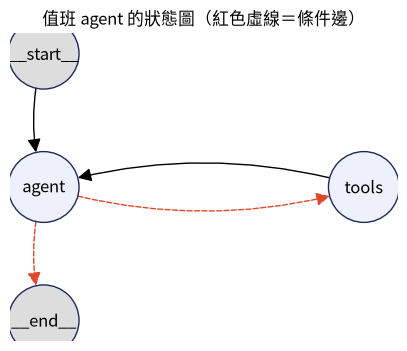

In [4]:
import matplotlib.pyplot as plt
import networkx as nx

from course_utils.viz import setup_cjk

setup_cjk()

from langgraph.checkpoint.memory import InMemorySaver

graph = builder.compile(checkpointer=InMemorySaver())
g = graph.get_graph()
G = nx.DiGraph()
for e in g.edges:
    G.add_edge(e.source, e.target, conditional=e.conditional)

pos = {"__start__": (0, 2), "agent": (0, 1), "tools": (1.2, 1), "__end__": (0, 0)}
fig, ax = plt.subplots(figsize=(5, 4))
nx.draw_networkx_nodes(G, pos, node_color=["#eef1fb" if n in ("agent", "tools") else "#dddddd" for n in G.nodes],
                       edgecolors="#1f2a5c", node_size=2600, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
solid = [(u, v) for u, v, d in G.edges(data=True) if not d["conditional"]]
dashed = [(u, v) for u, v, d in G.edges(data=True) if d["conditional"]]
nx.draw_networkx_edges(G, pos, edgelist=solid, ax=ax, arrowsize=20, node_size=2600, connectionstyle="arc3,rad=0.15")
nx.draw_networkx_edges(G, pos, edgelist=dashed, style="dashed", edge_color="#e0482c", ax=ax, arrowsize=20,
                       node_size=2600, connectionstyle="arc3,rad=0.15")
ax.set_title("值班 agent 的狀態圖（紅色虛線＝條件邊）")
ax.axis("off")
plt.show()

## Step 5：thread_id——同一本存檔才記得前文

編譯時給了 `InMemorySaver`，每次 `invoke` 都要帶一個 `thread_id`。
先在 thread「ticket-42」問連線池，接著問「那它的錯誤率呢？」——「它」指的是什麼，只有記得前文才知道。

In [5]:
cfg42 = {"configurable": {"thread_id": "ticket-42"}, "recursion_limit": 10}

out = graph.invoke({"messages": [("user", "order-db-proxy 的 pool_used 現在多少？")]}, cfg42)
print("第一問：", out["messages"][-1].content)

out = graph.invoke({"messages": [("user", "那它的 error_rate 呢？")]}, cfg42)
print("第二問：", out["messages"][-1].content)
print("這個 thread 目前有", len(out["messages"]), "則訊息")

第一問： order-db-proxy 的 pool_used 現在是 50，這是它的上限。
第二問： order-api 的 error_rate 現在是 27.1%。
這個 thread 目前有 8 則訊息


第二次 `invoke` 只送了一句話，但 graph 先從 checkpointer 讀回 ticket-42 的最新狀態，再把新訊息**追加**上去（reducer 的功勞）。

換一個 thread 問同一句，模型就不知道「它」是誰了。

In [6]:
cfg99 = {"configurable": {"thread_id": "ticket-99"}, "recursion_limit": 10}
out99 = graph.invoke({"messages": [("user", "那它的 error_rate 呢？")]}, cfg99)
print("新 thread：", out99["messages"][-1].content)

新 thread： order-api 的 error_rate 最近的值為 27.1，目前的值為 27.1。


沒有前文時，小模型通常不會反問「它是誰？」，而是**自己猜一個服務**去查，然後很有自信地回答。這比答不出來更難察覺。

## Step 6：翻開存檔看看

`get_state_history` 會列出這個 thread 的每一張快照（新的在前）。每張都記了：當時有幾則訊息、下一個要跑哪個節點。

In [7]:
history = list(graph.get_state_history(cfg42))
for snap in history[::-1]:
    last = snap.values["messages"][-1] if snap.values.get("messages") else None
    kind = type(last).__name__ if last else "-"
    print(f"step {snap.metadata['step']:>2}｜{len(snap.values.get('messages', [])):>2} 則｜最後一則 {kind:<12}｜下一步 {snap.next}")

step -1｜ 0 則｜最後一則 -           ｜下一步 ('__start__',)
step  0｜ 1 則｜最後一則 HumanMessage｜下一步 ('agent',)
step  1｜ 2 則｜最後一則 AIMessage   ｜下一步 ('tools',)
step  2｜ 3 則｜最後一則 ToolMessage ｜下一步 ('agent',)
step  3｜ 4 則｜最後一則 AIMessage   ｜下一步 ()
step  4｜ 4 則｜最後一則 AIMessage   ｜下一步 ('__start__',)
step  5｜ 5 則｜最後一則 HumanMessage｜下一步 ('agent',)
step  6｜ 6 則｜最後一則 AIMessage   ｜下一步 ('tools',)
step  7｜ 7 則｜最後一則 ToolMessage ｜下一步 ('agent',)
step  8｜ 8 則｜最後一則 AIMessage   ｜下一步 ()


畫成圖：橫軸是快照順序，縱軸是 messages 數量，顏色是「下一步要跑的節點」。兩個問題各自是一段階梯。

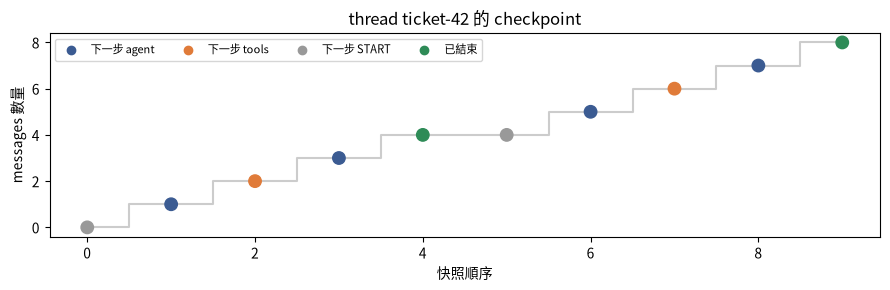

In [8]:
snaps_sorted = history[::-1]
colors = {"agent": "#3b5b92", "tools": "#e07b39", "__start__": "#999999"}
xs = range(len(snaps_sorted))
ys = [len(s.values.get("messages", [])) for s in snaps_sorted]
cs = [colors.get(s.next[0], "#2e8b57") if s.next else "#2e8b57" for s in snaps_sorted]
fig, ax = plt.subplots(figsize=(9, 3))
ax.step(xs, ys, where="mid", color="#cccccc")
ax.scatter(xs, ys, c=cs, s=80, zorder=3)
for label, c in [("下一步 agent", "#3b5b92"), ("下一步 tools", "#e07b39"), ("下一步 START", "#999999"), ("已結束", "#2e8b57")]:
    ax.scatter([], [], c=c, label=label)
ax.set_xlabel("快照順序")
ax.set_ylabel("messages 數量")
ax.set_title("thread ticket-42 的 checkpoint")
ax.legend(fontsize=8, ncol=4, loc="upper left")
plt.tight_layout()
plt.show()

## Step 7：時光旅行——從過去的快照重跑

找到第一問「模型剛決定要呼叫工具、還沒執行」那張快照（下一步是 tools），用它的 `checkpoint_id` 再 invoke 一次。
graph 會從那裡接著跑，產生一條新的分支；原本的歷史不會被改掉。

In [9]:
fork_from = next(s for s in snaps_sorted if s.next == ("tools",))
print("回到：step", fork_from.metadata["step"], "，下一步", fork_from.next)
replay = graph.invoke(None, fork_from.config)
print("重跑後的回答：", replay["messages"][-1].content)
print("thread 的快照數：", len(history), "→", len(list(graph.get_state_history(cfg42))))

回到：step 1 ，下一步 ('tools',)
重跑後的回答： order-db-proxy 的 pool_used 現在是 50，上限也是 50。
thread 的快照數： 10 → 13


這就是投影片上說的「時光旅行」：出錯時回到某一步，改了狀態（`graph.update_state`）或換個工具結果，再從那裡分岔出去。
正式環境把 `InMemorySaver` 換成 `PostgresSaver`，存檔就能跨行程、跨機器保留——程式碼只改一行。

## Step 8：recursion_limit——LangGraph 的保險絲

`recursion_limit` 限制一次 invoke 最多走幾步（每跑一個節點算一步）。設成 2：agent → tools 之後就沒額度回到 agent，直接拋出例外。

In [10]:
from langgraph.errors import GraphRecursionError

try:
    graph.invoke({"messages": [("user", "payment-api 的錯誤率是多少？")]},
                 {"configurable": {"thread_id": "ticket-limit"}, "recursion_limit": 2})
except GraphRecursionError as exc:
    print("擋下來了：", str(exc).splitlines()[0])

擋下來了： Recursion limit of 2 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


01 的 `max_steps` 是自己寫的，這裡是框架內建。不管哪一種，**一定要設**：模型反覆呼叫同一個工具的時候，只有它能停下來。

## 試試看

1. 把 `State` 的 `messages` 改成沒有 reducer 的 `list`，重跑 Step 5，第二問發生了什麼？
2. 在 Step 7 之前用 `graph.update_state(fork_from.config, {"messages": [...]})` 改掉模型要呼叫的工具參數（例如改查 order-api），再從新的快照重跑。
3. 再加一個節點 `summarize`：結束前把整段對話濃縮成一句寫進狀態的新欄位 `summary`。

## 小結

- 狀態圖＝狀態＋節點＋邊；LangGraph 幫你加上 reducer、checkpoint、保險絲。
- checkpointer 每一步存一張快照；`thread_id` 決定讀哪一本存檔，對話能中斷再接回、也能回到過去分岔。
- 下一本 05 用同一套機制做「暫停等人點頭」：寫入動作走固定的 審批 → 執行 → 驗證。